In [1]:
import importlib
import mininn.layers
import mininn

importlib.reload(mininn.layers)
importlib.reload(mininn.containers)

# from mininn import InceptionWBatchNorm2D

<module 'mininn.containers' from '/home/devansh/main/machine_learning/deep-learning-lab/DeepVisionLab/mininn/containers.py'>

In [2]:
import torch
import mininn as mini
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split, Subset
from copy import copy
import time
import matplotlib.pyplot as plt


device = "cuda"
g = torch.Generator(device=device).manual_seed(42)
data_root = "../data_1"

In [3]:
train_data = datasets.CIFAR100(
    root=data_root,
    train=True,
    download=True,
    transform=transforms.ToTensor(),
)

loader = DataLoader(
    train_data,
    batch_size=32,
    shuffle=True,
    generator=torch.Generator().manual_seed(42),
    num_workers=0,
)

# Fetch once; reuse these exact tensors for every update.
images, labels = next(iter(loader))
images = images.to(device)
labels = labels.to(device)

print(images.shape)  # (32, 3, 32, 32)
print(labels.shape)  # (32,)
print(labels.min().item(), labels.max().item())  # within 0–99

torch.Size([32, 3, 32, 32])
torch.Size([32])
1 99


In [4]:
batch_size = 32

train_data = datasets.CIFAR100(
    root=data_root,
    train=True,
    download=True,
    transform=transforms.ToTensor(),
)

train_subset, val_subset = random_split(
    train_data,
    [45000, 5000],
    generator=torch.Generator().manual_seed(42),
)

# Flip-only training dataset
flip_dataset = copy(train_data)
flip_dataset.transform = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
])

# Crop + flip training dataset
crop_dataset = copy(train_data)
crop_dataset.transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
])

flip_train_subset = Subset(flip_dataset, train_subset.indices)
crop_train_subset = Subset(crop_dataset, train_subset.indices)

augmented_train_loader = DataLoader(
    flip_train_subset,
    batch_size=batch_size,
    shuffle=True,
    generator=torch.Generator().manual_seed(43),
)

augmented_cropped_train_loader = DataLoader(
    crop_train_subset,
    batch_size=batch_size,
    shuffle=True,
    generator=torch.Generator().manual_seed(43),
)

# Evaluation: no random augmentation
train_loader = DataLoader(
    train_subset, batch_size=batch_size, shuffle=False
)
val_loader = DataLoader(
    val_subset, batch_size=batch_size, shuffle=False
)

test_dataset = datasets.CIFAR100(
    root=data_root,
    train=False,
    download=True,
    transform=transforms.ToTensor(),
)
test_loader = DataLoader(
    test_dataset, batch_size=batch_size, shuffle=False
)

# Verify the split actually used for training.
train_ids = set(train_subset.indices)
val_ids = set(val_subset.indices)

assert train_ids.isdisjoint(val_ids)
assert set(crop_train_subset.indices) == train_ids
assert set(flip_train_subset.indices) == train_ids

for name, loader in [
    ("Flip training", augmented_train_loader),
    ("Crop training", augmented_cropped_train_loader),
    ("Validation", val_loader),
    ("Test", test_loader),
]:
    print(f"{name}: {len(loader.dataset):,}")

Flip training: 45,000
Crop training: 45,000
Validation: 5,000
Test: 10,000


In [5]:
def train_epochs(model_t, optimizer_t, checkpoint_name="", data=augmented_train_loader, epoch_start=1, n_epochs=10):
    print(f"{checkpoint_name}")
    
    best_val = float("-inf")
    
    for epoch in range(epoch_start, epoch_start + n_epochs):
    
        # for calculating training time
        if str(device).startswith("cuda"):
            torch.cuda.synchronize()
        epoch_start = time.perf_counter()
            
        train_loss = mini.train_one_epoch(
            model_t, data,
            optimizer_t, device
        )
        metrics = mini.evaluate(model_t, val_loader, device)
        
        # After validation, before checkpoint saving:
        if str(device).startswith("cuda"):
            torch.cuda.synchronize()
        epoch_seconds = time.perf_counter() - epoch_start

        if metrics["accuracy"] > best_val:
            best_val = metrics["accuracy"]
            mini.save_checkpoint(
                checkpoint_name,
                model_t,
                optimizer=optimizer_t,
                epoch=epoch
            )

        print(
            f"Epoch {epoch} | Train loss: {train_loss:.4f} | "
            f"Val loss: {metrics['loss']:.4f} | "
            f"Val accuracy: {metrics['accuracy']:.2f}%"
            f" | Time: {epoch_seconds:.1f}s"
        )

    best_epoch = mini.load_checkpoint(
        checkpoint_name,
        model_t,
        optimizer=optimizer_t,
        device=device
    )

    train_metrics = mini.evaluate(model_t, train_loader, device)
    val_metrics = mini.evaluate(model_t, val_loader, device)

    print(f"\nRestored epoch: {best_epoch}")
    print(f"Training accuracy: {train_metrics['accuracy']:.2f}%")
    print(f"Validation accuracy: {val_metrics['accuracy']:.2f}%")

In [6]:
def build_model():

    layers = [
        mini.Conv2D(3, 64, 3, padding=1, device=device, generator=g),
        mini.BatchNorm2D(64, device=device),
        mini.ReLU(),
        
        # mini.Inception(in_channels=64, ch1=32, ch3_reduce=32, ch3=48, ch5_reduce=8, ch5=16, pool_proj=32, device=device, generator=g),
        # mini.Inception(in_channels=128, ch1=32, ch3_reduce=32, ch3=48, ch5_reduce=8, ch5=16, pool_proj=32, device=device, generator=g),
        
        mini.InceptionWBatchNorm2D(in_channels=64, ch1=32, ch3_reduce=32, ch3=48, ch5_reduce=8, ch5=16, pool_proj=32, device=device, generator=g),
        mini.InceptionWBatchNorm2D(in_channels=128, ch1=32, ch3_reduce=32, ch3=48, ch5_reduce=8, ch5=16, pool_proj=32, device=device, generator=g),
        
        mini.MaxPool2D(2, 2, 0),
        
        # mini.Inception(in_channels=128, ch1=64, ch3_reduce=64, ch3=96, ch5_reduce=16, ch5=32, pool_proj=64, device=device, generator=g),
        # mini.Inception(in_channels=256, ch1=64, ch3_reduce=64, ch3=96, ch5_reduce=16, ch5=32, pool_proj=64, device=device, generator=g),
        
        mini.InceptionWBatchNorm2D(in_channels=128, ch1=64, ch3_reduce=64, ch3=96, ch5_reduce=16, ch5=32, pool_proj=64, device=device, generator=g),
        mini.InceptionWBatchNorm2D(in_channels=256, ch1=64, ch3_reduce=64, ch3=96, ch5_reduce=16, ch5=32, pool_proj=64, device=device, generator=g),
        
        mini.MaxPool2D(2, 2, 0),
        
        # mini.Inception(in_channels=256, ch1=96, ch3_reduce=96, ch3=144, ch5_reduce=24, ch5=48, pool_proj=96, device=device, generator=g),
        # mini.Inception(in_channels=384, ch1=96, ch3_reduce=96, ch3=144, ch5_reduce=24, ch5=48, pool_proj=96, device=device, generator=g),
        
        mini.InceptionWBatchNorm2D(in_channels=256, ch1=96, ch3_reduce=96, ch3=144, ch5_reduce=24, ch5=48, pool_proj=96, device=device, generator=g),
        mini.InceptionWBatchNorm2D(in_channels=384, ch1=96, ch3_reduce=96, ch3=144, ch5_reduce=24, ch5=48, pool_proj=96, device=device, generator=g),
        
        mini.GlobalAvgPool2D(),
        mini.Linear(384, 100, device=device, generator=g)
    ]

    return mini.Sequential(layers)

In [20]:
model_inception_cropped = build_model()
total_params = sum(p.numel() for p in model_inception_cropped.parameters())
print(f"Total parameters: {total_params:,}")

Total parameters: 818,500


In [21]:
x = torch.randn(2, 3, 32, 32, device=device)
targets = torch.tensor([0, 99], device=device)

logits = model_base(x)
assert logits.shape == (2, 100)

loss = torch.nn.functional.cross_entropy(logits, targets)
loss.backward()

for p in model_base.parameters():
    assert p.grad is not None
    assert torch.isfinite(p.grad).all()

print("Logits:", logits.shape)
print("Loss:", loss.item())
print("All parameter gradients are finite.")

Logits: torch.Size([2, 100])
Loss: 16.39423370361328
All parameter gradients are finite.


In [9]:
optimizer_base = mini.AdamW(
    model_base.parameters(),
    learning_rate=0.001,
    weight_decay=0.0,
)

model_base.train()

for step in range(201):
    if step > 0:
        optimizer_base.zero_grad()

        logits = model_base(images)
        loss = torch.nn.functional.cross_entropy(logits, labels)
        loss.backward()
        optimizer_base.step()

    if step in (0, 50, 100, 200):
        with torch.no_grad():
            logits = model_base(images)
            loss = torch.nn.functional.cross_entropy(logits, labels)
            accuracy = (
                (logits.argmax(dim=1) == labels).float().mean().item() * 100
            )

        print(
            f"Step {step:3d}/200 | "
            f"Loss: {loss.item():.6f} | "
            f"Batch accuracy: {accuracy:6.2f}%"
        )

Step   0/200 | Loss: 5.290871 | Batch accuracy:   0.00%
Step  50/200 | Loss: 0.199779 | Batch accuracy:  93.75%
Step 100/200 | Loss: 0.000495 | Batch accuracy: 100.00%
Step 200/200 | Loss: 0.000038 | Batch accuracy: 100.00%


In [ ]:
optimizer_inception_cropped = mini.AdamW(
    model_inception_cropped.parameters(), learning_rate=0.001, weight_decay=0.0001
)
# best_val_dropout = float("-inf")

train_epochs(model_inception_cropped, optimizer_inception_base, "best_inception_cifar100_crop_ep10.pt", 1, 10)

best_inception_cifar100_ep10.pt
Epoch 1 | Train loss: 3.9006 | Val loss: 3.5059 | Val accuracy: 15.62% | Time: 96.2s
Epoch 2 | Train loss: 3.2595 | Val loss: 2.9903 | Val accuracy: 24.80% | Time: 95.6s
Epoch 3 | Train loss: 2.7533 | Val loss: 2.7236 | Val accuracy: 31.92% | Time: 96.4s
Epoch 4 | Train loss: 2.4242 | Val loss: 2.4323 | Val accuracy: 38.12% | Time: 95.4s
Epoch 5 | Train loss: 2.1792 | Val loss: 2.2442 | Val accuracy: 41.66% | Time: 96.5s
Epoch 6 | Train loss: 2.0019 | Val loss: 2.0950 | Val accuracy: 44.94% | Time: 97.5s
Epoch 7 | Train loss: 1.8633 | Val loss: 2.0016 | Val accuracy: 46.94% | Time: 96.8s
Epoch 8 | Train loss: 1.7377 | Val loss: 2.0137 | Val accuracy: 47.84% | Time: 101.4s
Epoch 9 | Train loss: 1.6384 | Val loss: 1.8784 | Val accuracy: 50.22% | Time: 97.1s
Epoch 10 | Train loss: 1.5491 | Val loss: 1.8901 | Val accuracy: 50.42% | Time: 97.5s

Restored epoch: 10
Training accuracy: 60.66%
Validation accuracy: 50.42%


In [ ]:
optimizer_inception_cropped.learning_rate = 0.0001

In [ ]:
train_epochs(model_inception_cropped, optimizer_inception_base, "best_inception_cifar100_crop_ep20.pt", 11, 10)

best_inception_cifar100_ep20.pt
Epoch 11 | Train loss: 1.1769 | Val loss: 1.7387 | Val accuracy: 55.38% | Time: 96.1s
Epoch 12 | Train loss: 1.1029 | Val loss: 1.7441 | Val accuracy: 56.36% | Time: 96.0s
Epoch 13 | Train loss: 1.0578 | Val loss: 1.7835 | Val accuracy: 56.08% | Time: 94.9s
Epoch 14 | Train loss: 1.0269 | Val loss: 1.8073 | Val accuracy: 56.74% | Time: 95.1s
Epoch 15 | Train loss: 1.0046 | Val loss: 1.7884 | Val accuracy: 56.62% | Time: 94.6s
Epoch 16 | Train loss: 0.9746 | Val loss: 1.8253 | Val accuracy: 56.50% | Time: 94.9s
Epoch 17 | Train loss: 0.9576 | Val loss: 1.8386 | Val accuracy: 56.84% | Time: 94.3s
Epoch 18 | Train loss: 0.9312 | Val loss: 1.8690 | Val accuracy: 56.70% | Time: 95.1s
Epoch 19 | Train loss: 0.9135 | Val loss: 1.8555 | Val accuracy: 57.08% | Time: 94.1s
Epoch 20 | Train loss: 0.8915 | Val loss: 1.8723 | Val accuracy: 56.68% | Time: 94.7s

Restored epoch: 19
Training accuracy: 74.15%
Validation accuracy: 57.08%


In [22]:
model_inception_base = build_model()
total_params = sum(p.numel() for p in model_cropped.parameters())
print(f"Total parameters: {total_params:,}")

Total parameters: 818,500


In [24]:
optimizer_inception_base = mini.AdamW(
    model_inception_base.parameters(), learning_rate=0.001, weight_decay=0.0001
)

In [ ]:
train_epochs(model_inception_base, optimizer_inception_base, "best_inception_cifar100_base_seed42.pt")

best_inception_cifar100_base_seed42.pt
Epoch 1 | Train loss: 3.9623 | Val loss: 3.5226 | Val accuracy: 15.04% | Time: 94.5s
Epoch 2 | Train loss: 3.1807 | Val loss: 2.8592 | Val accuracy: 27.76% | Time: 94.1s
Epoch 3 | Train loss: 2.5825 | Val loss: 2.4429 | Val accuracy: 36.02% | Time: 93.4s
Epoch 4 | Train loss: 2.2235 | Val loss: 2.2024 | Val accuracy: 41.82% | Time: 94.6s
Epoch 5 | Train loss: 1.9660 | Val loss: 2.0452 | Val accuracy: 44.96% | Time: 98.6s
Epoch 6 | Train loss: 1.7722 | Val loss: 2.0038 | Val accuracy: 46.42% | Time: 97.0s
Epoch 7 | Train loss: 1.6067 | Val loss: 1.9160 | Val accuracy: 49.00% | Time: 92.5s
Epoch 8 | Train loss: 1.4744 | Val loss: 1.8854 | Val accuracy: 50.14% | Time: 93.5s
Epoch 9 | Train loss: 1.3485 | Val loss: 1.8492 | Val accuracy: 50.64% | Time: 93.3s
Epoch 10 | Train loss: 1.2377 | Val loss: 1.8276 | Val accuracy: 52.34% | Time: 93.3s

Restored epoch: 10
Training accuracy: 69.41%
Validation accuracy: 52.34%


In [26]:
optimizer_inception_base.learning_rate = 0.0001

In [27]:
train_epochs(model_inception_base, optimizer_inception_base, "best_inception_cifar100_base_seed42_ep20.pt",11,10)

best_inception_cifar100_base_seed42_ep20.pt
Epoch 11 | Train loss: 0.7970 | Val loss: 1.7569 | Val accuracy: 56.68% | Time: 93.8s
Epoch 12 | Train loss: 0.6890 | Val loss: 1.8108 | Val accuracy: 56.72% | Time: 93.0s
Epoch 13 | Train loss: 0.6320 | Val loss: 1.8550 | Val accuracy: 57.08% | Time: 93.6s
Epoch 14 | Train loss: 0.5815 | Val loss: 1.9319 | Val accuracy: 56.36% | Time: 93.2s
Epoch 15 | Train loss: 0.5419 | Val loss: 1.9587 | Val accuracy: 57.08% | Time: 93.5s
Epoch 16 | Train loss: 0.4997 | Val loss: 2.0396 | Val accuracy: 56.30% | Time: 91.9s
Epoch 17 | Train loss: 0.4655 | Val loss: 2.0644 | Val accuracy: 56.76% | Time: 89.6s
Epoch 18 | Train loss: 0.4273 | Val loss: 2.1732 | Val accuracy: 56.16% | Time: 89.3s
Epoch 19 | Train loss: 0.3934 | Val loss: 2.2585 | Val accuracy: 56.46% | Time: 89.8s
Epoch 20 | Train loss: 0.3588 | Val loss: 2.3294 | Val accuracy: 55.64% | Time: 89.5s

Restored epoch: 13
Training accuracy: 83.23%
Validation accuracy: 57.08%


In [28]:
parameter_count = sum(
    p.numel() for p in model_cropped.parameters()
    if p.requires_grad
)

print(f"Trainable parameters: {parameter_count:,}")

Trainable parameters: 818,500


In [20]:
g.manual_seed(42)
model_adam = build_model()

optimizer_adam = mini.Adam(
    model_adam.parameters(),
    learning_rate=0.001,
)

parameter_count = sum(
    p.numel() for p in model_adam.parameters()
    if p.requires_grad
)

print(f"Trainable parameters: {parameter_count:,}")

Trainable parameters: 818,500


In [ ]:
train_epochs(model_adam, optimizer_adam, "best_inception_cifar100_crop_adam_seed42.pt",1,10)


best_inception_cifar100_crop_adam_seed42.pt
Epoch 1 | Train loss: 3.9532 | Val loss: 3.6288 | Val accuracy: 12.98% | Time: 93.2s
Epoch 2 | Train loss: 3.3044 | Val loss: 3.1249 | Val accuracy: 23.66% | Time: 92.0s
Epoch 3 | Train loss: 2.8167 | Val loss: 2.7124 | Val accuracy: 32.04% | Time: 92.8s
Epoch 4 | Train loss: 2.4548 | Val loss: 2.3621 | Val accuracy: 38.50% | Time: 92.9s
Epoch 5 | Train loss: 2.2013 | Val loss: 2.2763 | Val accuracy: 41.92% | Time: 93.7s
Epoch 6 | Train loss: 2.0128 | Val loss: 2.1502 | Val accuracy: 44.18% | Time: 93.2s
Epoch 7 | Train loss: 1.8600 | Val loss: 2.0323 | Val accuracy: 46.82% | Time: 93.0s
Epoch 8 | Train loss: 1.7378 | Val loss: 2.0498 | Val accuracy: 47.00% | Time: 93.4s
Epoch 9 | Train loss: 1.6300 | Val loss: 1.9688 | Val accuracy: 48.76% | Time: 93.8s
Epoch 10 | Train loss: 1.5359 | Val loss: 1.9822 | Val accuracy: 50.84% | Time: 93.2s

Restored epoch: 10
Training accuracy: 61.31%
Validation accuracy: 50.84%


In [24]:
checkpoint = "./checkpoints/best_inception_cifar100_crop_adam_ep10.pt"

restored_epoch = mini.load_checkpoint(
    checkpoint,
    model_adam,
    optimizer=optimizer_adam,
    device=device,
)

# Change LR after restoring the optimizer state.
optimizer_adam.learning_rate = 0.0001

print("Restored epoch:", restored_epoch)
print("Learning rate:", optimizer_adam.learning_rate)

assert restored_epoch == 10

Restored epoch: 10
Learning rate: 0.0001


In [25]:
train_epochs(
    model_adam,
    optimizer_adam,
    checkpoint_name="best_inception_cifar100_crop_adam_ep20.pt",
    data=augmented_cropped_train_loader,
    epoch_start=11,
    n_epochs=10,
)

best_inception_cifar100_crop_adam_ep20.pt
Epoch 11 | Train loss: 1.1562 | Val loss: 1.8119 | Val accuracy: 55.22% | Time: 90.0s
Epoch 12 | Train loss: 1.0778 | Val loss: 1.7886 | Val accuracy: 55.96% | Time: 89.0s
Epoch 13 | Train loss: 1.0361 | Val loss: 1.8290 | Val accuracy: 55.88% | Time: 89.6s
Epoch 14 | Train loss: 1.0045 | Val loss: 1.8169 | Val accuracy: 56.18% | Time: 90.7s
Epoch 15 | Train loss: 0.9728 | Val loss: 1.8723 | Val accuracy: 56.06% | Time: 89.8s
Epoch 16 | Train loss: 0.9517 | Val loss: 1.8811 | Val accuracy: 56.40% | Time: 89.9s
Epoch 17 | Train loss: 0.9252 | Val loss: 1.9158 | Val accuracy: 56.36% | Time: 88.2s
Epoch 18 | Train loss: 0.9047 | Val loss: 1.8875 | Val accuracy: 56.52% | Time: 89.0s
Epoch 19 | Train loss: 0.8847 | Val loss: 1.9162 | Val accuracy: 56.48% | Time: 88.8s
Epoch 20 | Train loss: 0.8600 | Val loss: 1.9344 | Val accuracy: 56.66% | Time: 89.1s

Restored epoch: 20
Training accuracy: 75.97%
Validation accuracy: 56.66%


In [26]:
model_adam.eval()

all_labels = []
all_predictions = []
all_confidences = []

with torch.no_grad():
    for images, labels in val_loader:
        logits = model_adam(images.to(device))
        probabilities = torch.softmax(logits, dim=1)
        confidences, predictions = probabilities.max(dim=1)

        all_labels.append(labels.detach().cpu())
        all_predictions.append(predictions.cpu())
        all_confidences.append(confidences.cpu())

all_labels = torch.cat(all_labels)
all_predictions = torch.cat(all_predictions)
all_confidences = torch.cat(all_confidences)

correct = all_predictions == all_labels
wrong = ~correct

print(f"Validation examples: {all_labels.numel():,}")
print(f"Accuracy: {correct.float().mean().item():.2%}")
print(f"Incorrect predictions: {wrong.sum().item():,}")

if wrong.any():
    print(
        "Mean confidence on incorrect predictions: "
        f"{all_confidences[wrong].mean().item():.2%}"
    )

# Indices refer to positions in the collected validation outputs.
wrong_indices = torch.where(wrong)[0]
ranked_wrong_indices = wrong_indices[
    all_confidences[wrong_indices].argsort(descending=True)
]

print("\nTop 10 most confident mistakes:")
for index in ranked_wrong_indices[:10]:
    print(
        f"Position {index.item():4d} | "
        f"True: {all_labels[index].item():2d} | "
        f"Predicted: {all_predictions[index].item():2d} | "
        f"Confidence: {all_confidences[index].item():.2%}"
    )

Validation examples: 5,000
Accuracy: 56.66%
Incorrect predictions: 2,167
Mean confidence on incorrect predictions: 58.87%

Top 10 most confident mistakes:
Position 2761 | True: 32 | Predicted: 91 | Confidence: 100.00%
Position  860 | True: 99 | Predicted: 75 | Confidence: 100.00%
Position 2311 | True: 82 | Predicted: 60 | Confidence: 100.00%
Position  563 | True: 76 | Predicted: 23 | Confidence: 99.99%
Position 3288 | True: 25 | Predicted: 20 | Confidence: 99.97%
Position 2413 | True: 47 | Predicted: 96 | Confidence: 99.96%
Position 2796 | True: 16 | Predicted:  9 | Confidence: 99.94%
Position 2866 | True: 71 | Predicted: 60 | Confidence: 99.94%
Position 3752 | True:  3 | Predicted: 43 | Confidence: 99.94%
Position 1100 | True: 35 | Predicted: 36 | Confidence: 99.90%


In [27]:
num_classes = 100

confusion = torch.bincount(
    all_labels * num_classes + all_predictions,
    minlength=num_classes**2,
).reshape(num_classes, num_classes)

tp = confusion.diag().float()
support = confusion.sum(dim=1)
predicted_count = confusion.sum(dim=0)

recall = tp / support.clamp_min(1)
precision = tp / predicted_count.clamp_min(1)

class_names = train_data.classes

print("10 lowest-recall classes:")
for class_id in torch.argsort(recall)[:10]:
    i = class_id.item()
    print(
        f"{class_names[i]:20s} | "
        f"Recall: {recall[i]:.2%} | "
        f"Precision: {precision[i]:.2%} | "
        f"Support: {support[i].item()}"
    )

10 lowest-recall classes:
otter                | Recall: 15.22% | Precision: 16.28% | Support: 46
seal                 | Recall: 15.56% | Precision: 21.21% | Support: 45
beaver               | Recall: 17.39% | Precision: 17.78% | Support: 46
lizard               | Recall: 21.28% | Precision: 30.30% | Support: 47
mouse                | Recall: 26.00% | Precision: 37.14% | Support: 50
boy                  | Recall: 31.48% | Precision: 45.95% | Support: 54
tulip                | Recall: 32.00% | Precision: 51.61% | Support: 50
man                  | Recall: 32.08% | Precision: 53.12% | Support: 53
kangaroo             | Recall: 34.69% | Precision: 48.57% | Support: 49
rabbit               | Recall: 35.19% | Precision: 43.18% | Support: 54


In [28]:
print("Most common confusion for each low-recall class:")

for class_id in torch.argsort(recall)[:10]:
    i = class_id.item()
    mistakes = confusion[i].clone()
    mistakes[i] = 0
    j = mistakes.argmax().item()

    print(
        f"{class_names[i]:12s} → {class_names[j]:12s} | "
        f"{mistakes[j].item()} / {support[i].item()} examples"
    )

Most common confusion for each low-recall class:
otter        → beaver       | 4 / 46 examples
seal         → otter        | 8 / 45 examples
beaver       → shrew        | 6 / 46 examples
lizard       → shrew        | 3 / 47 examples
mouse        → shrew        | 6 / 50 examples
boy          → girl         | 8 / 54 examples
tulip        → rose         | 10 / 50 examples
man          → woman        | 14 / 53 examples
kangaroo     → rabbit       | 3 / 49 examples
rabbit       → fox          | 3 / 54 examples


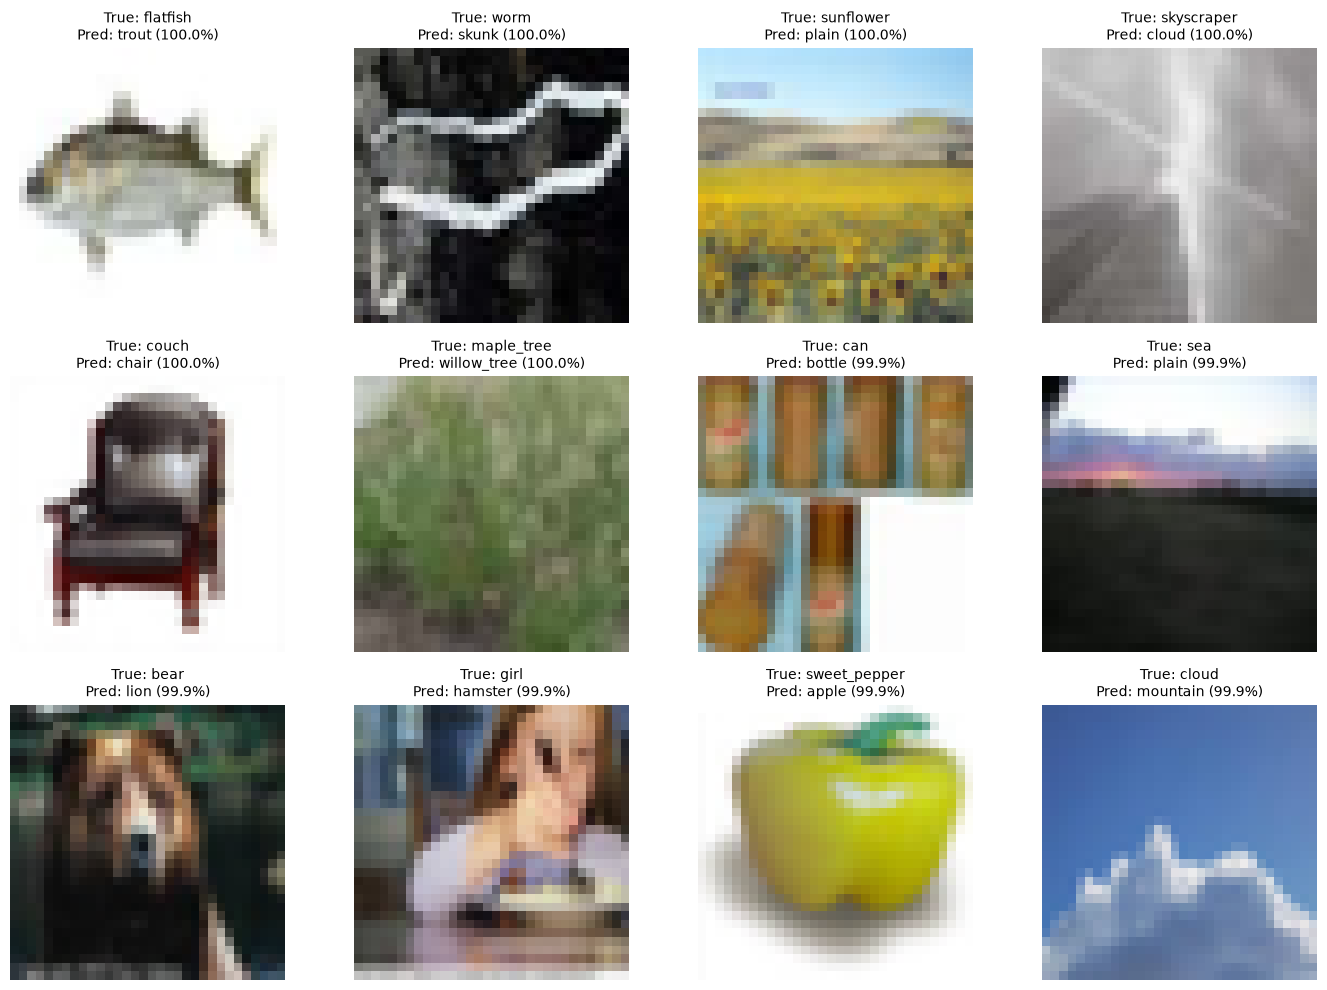

In [29]:
wrong_indices = torch.where(
    all_predictions != all_labels
)[0]

ranked_indices = wrong_indices[
    torch.argsort(
        all_confidences[wrong_indices],
        descending=True,
    )
][:12]

fig, axes = plt.subplots(3, 4, figsize=(14, 10))

for ax, position in zip(axes.flat, ranked_indices):
    i = position.item()
    image, label = val_loader.dataset[i]
    predicted = all_predictions[i].item()
    confidence = all_confidences[i].item()

    assert int(label) == all_labels[i].item()

    ax.imshow(image.detach().cpu().permute(1, 2, 0))
    ax.set_title(
        f"True: {class_names[int(label)]}\n"
        f"Pred: {class_names[predicted]} ({confidence:.1%})",
        fontsize=10,
    )
    ax.axis("off")

for ax in axes.flat[len(ranked_indices):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [30]:
model_adam.eval()

all_probs = []
all_targets = []
nll_sum = 0.0

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)
        labels = labels.to(device)

        logits = model_adam(images)

        # Compute NLL directly from logits for numerical stability.
        nll_sum += torch.nn.functional.cross_entropy(
            logits, labels, reduction="sum"
        ).item()

        all_probs.append(logits.softmax(dim=1).cpu())
        all_targets.append(labels.cpu())

probs = torch.cat(all_probs)
targets = torch.cat(all_targets)

confidence, predictions = probs.max(dim=1)
correct = predictions.eq(targets)
nll = nll_sum / targets.numel()

# Multiclass Brier score: sum over classes, then mean over examples.
one_hot = torch.nn.functional.one_hot(
    targets, num_classes=probs.shape[1]
).to(probs.dtype)

brier = (probs - one_hot).square().sum(dim=1).mean().item()

# Top-label ECE using 15 equal-width confidence bins.
n_bins = 15
bin_ids = (confidence * n_bins).long().clamp(max=n_bins - 1)
ece = 0.0

print("Confidence bins:")
for i in range(n_bins):
    mask = bin_ids.eq(i)
    count = mask.sum().item()

    if count == 0:
        continue

    bin_accuracy = correct[mask].float().mean().item()
    bin_confidence = confidence[mask].mean().item()
    ece += (count / targets.numel()) * abs(
        bin_accuracy - bin_confidence
    )

    print(
        f"[{i / n_bins:.2f}, {(i + 1) / n_bins:.2f}"
        f"{']' if i == n_bins - 1 else ')'} | "
        f"n={count:4d} | Accuracy={bin_accuracy:.2%} | "
        f"Confidence={bin_confidence:.2%}"
    )

print(f"\nValidation examples: {targets.numel():,}")
print(f"Accuracy:           {correct.float().mean().item():.2%}")
print(f"Mean confidence:    {confidence.mean().item():.2%}")
print(f"NLL:                {nll:.4f}")
print(f"Brier score:        {brier:.4f}")
print(f"ECE (15 bins):      {ece:.2%}")

Confidence bins:
[0.07, 0.13) | n=   4 | Accuracy=0.00% | Confidence=12.09%
[0.13, 0.20) | n=  36 | Accuracy=8.33% | Confidence=17.43%
[0.20, 0.27) | n= 135 | Accuracy=13.33% | Confidence=23.54%
[0.27, 0.33) | n= 210 | Accuracy=14.76% | Confidence=30.03%
[0.33, 0.40) | n= 237 | Accuracy=23.21% | Confidence=36.97%
[0.40, 0.47) | n= 296 | Accuracy=23.99% | Confidence=43.44%
[0.47, 0.53) | n= 350 | Accuracy=33.14% | Confidence=50.08%
[0.53, 0.60) | n= 326 | Accuracy=35.28% | Confidence=56.49%
[0.60, 0.67) | n= 295 | Accuracy=40.00% | Confidence=63.28%
[0.67, 0.73) | n= 314 | Accuracy=43.95% | Confidence=70.12%
[0.73, 0.80) | n= 305 | Accuracy=51.48% | Confidence=76.61%
[0.80, 0.87) | n= 331 | Accuracy=57.40% | Confidence=83.38%
[0.87, 0.93) | n= 393 | Accuracy=66.92% | Confidence=90.33%
[0.93, 1.00] | n=1768 | Accuracy=88.12% | Confidence=98.50%

Validation examples: 5,000
Accuracy:           56.66%
Mean confidence:    73.80%
NLL:                1.9344
Brier score:        0.6044
ECE (15 b

In [31]:
import time
import statistics
import torch

model_adam.eval()
parameter = model_adam.parameters()[0]
benchmark_device = parameter.device
is_cuda = benchmark_device.type == "cuda"

print("Device:", benchmark_device)
if is_cuda:
    print("GPU:", torch.cuda.get_device_name(benchmark_device))
print("Dtype:", parameter.dtype)

def synchronize():
    if is_cuda:
        torch.cuda.synchronize(benchmark_device)

@torch.inference_mode()
def benchmark(batch_size, warmup=20, repeats=100):
    x = torch.randn(
        batch_size, 3, 32, 32,
        device=benchmark_device,
        dtype=parameter.dtype,
    )

    for _ in range(warmup):
        model_adam(x)
    synchronize()

    if is_cuda:
        torch.cuda.reset_peak_memory_stats(benchmark_device)
        baseline_memory = torch.cuda.memory_allocated(benchmark_device)

    durations = []

    for _ in range(repeats):
        synchronize()
        start = time.perf_counter()

        output = model_adam(x)

        synchronize()
        durations.append(time.perf_counter() - start)
        del output

    mean_seconds = statistics.mean(durations)
    median_ms = statistics.median(durations) * 1000
    p95_ms = sorted(durations)[
        int(0.95 * (len(durations) - 1))
    ] * 1000

    print(f"\nBatch size: {batch_size}")
    print(f"Mean batch latency:   {mean_seconds * 1000:.3f} ms")
    print(f"Median batch latency: {median_ms:.3f} ms")
    print(f"P95 batch latency:    {p95_ms:.3f} ms")
    print(f"Throughput:           {batch_size / mean_seconds:.1f} images/s")

    if is_cuda:
        peak = torch.cuda.max_memory_allocated(benchmark_device)
        print(f"Peak allocated GPU memory: {peak / 2**20:.2f} MiB")
        print(
            "Peak increase above baseline: "
            f"{(peak - baseline_memory) / 2**20:.2f} MiB"
        )

for batch_size in (1, 32):
    benchmark(batch_size)

Device: cuda:0
GPU: NVIDIA GeForce RTX 5070 Ti Laptop GPU
Dtype: torch.float32

Batch size: 1
Mean batch latency:   3.295 ms
Median batch latency: 3.180 ms
P95 batch latency:    4.372 ms
Throughput:           303.5 images/s
Peak allocated GPU memory: 179.65 MiB
Peak increase above baseline: 7.56 MiB

Batch size: 32
Mean batch latency:   25.796 ms
Median batch latency: 25.580 ms
P95 batch latency:    27.194 ms
Throughput:           1240.5 images/s
Peak allocated GPU memory: 606.92 MiB
Peak increase above baseline: 229.06 MiB


In [8]:
model_adam_bn = build_model()

parameter_count = sum(
    p.numel() for p in model_adam_bn.parameters()
    if p.requires_grad
)

print(f"Trainable parameters: {parameter_count:,}")

Trainable parameters: 822,660


In [9]:
block = model_adam_bn.layers[3]

for name in ("a", "b", "c", "d"):
    branch = getattr(block, f"branch_{name}")

    print(f"\nBranch {name}:")
    for i, layer in enumerate(branch.layers):
        print(i, type(layer).__name__)


Branch a:
0 Conv2D
1 BatchNorm2D
2 ReLU

Branch b:
0 Conv2D
1 BatchNorm2D
2 ReLU
3 Conv2D
4 BatchNorm2D
5 ReLU

Branch c:
0 Conv2D
1 BatchNorm2D
2 ReLU
3 Conv2D
4 BatchNorm2D
5 ReLU

Branch d:
0 MaxPool2D
1 Conv2D
2 BatchNorm2D
3 ReLU


In [11]:
optimizer_adam_bn = mini.Adam(
    model_adam_bn.parameters(),
    learning_rate=0.001,
)

In [ ]:
train_epochs(model_adam_bn, optimizer_adam_bn, "best_inception_bn_cifar100_crop_adam_seed42_10ep.pt", 1, 10)

best_inception_bn_cifar100_crop_adam_seed42_20ep.pt
Epoch 1 | Train loss: 3.2956 | Val loss: 3.1128 | Val accuracy: 24.70% | Time: 126.2s
Epoch 2 | Train loss: 2.4175 | Val loss: 2.3616 | Val accuracy: 38.80% | Time: 125.5s
Epoch 3 | Train loss: 2.0137 | Val loss: 1.9491 | Val accuracy: 46.44% | Time: 125.5s
Epoch 4 | Train loss: 1.7586 | Val loss: 1.8081 | Val accuracy: 50.60% | Time: 125.7s
Epoch 5 | Train loss: 1.5895 | Val loss: 1.6897 | Val accuracy: 54.04% | Time: 124.8s
Epoch 6 | Train loss: 1.4507 | Val loss: 1.6459 | Val accuracy: 55.72% | Time: 124.1s
Epoch 7 | Train loss: 1.3315 | Val loss: 1.6862 | Val accuracy: 55.30% | Time: 124.2s
Epoch 8 | Train loss: 1.2393 | Val loss: 1.5024 | Val accuracy: 59.14% | Time: 124.2s
Epoch 9 | Train loss: 1.1575 | Val loss: 1.4996 | Val accuracy: 60.38% | Time: 125.6s
Epoch 10 | Train loss: 1.0797 | Val loss: 1.4892 | Val accuracy: 61.18% | Time: 126.6s

Restored epoch: 10
Training accuracy: 73.47%
Validation accuracy: 61.18%


In [32]:
checkpoint = "./checkpoints/best_inception_bn_cifar100_crop_adam_seed42_10ep.pt"

restored_epoch = mini.load_checkpoint(
    checkpoint,
    model_adam_bn,
    optimizer=optimizer_adam_bn,
    device=device,
)

# Change LR after restoring the optimizer state.
optimizer_adam_bn.learning_rate = 0.0001

print("Restored epoch:", restored_epoch)
print("Learning rate:", optimizer_adam_bn.learning_rate)

assert restored_epoch == 10

Restored epoch: 10
Learning rate: 0.0001


In [33]:
train_epochs(model_adam_bn, optimizer_adam_bn, "best_inception_bn_cifar100_crop_adam_20ep.pt", augmented_cropped_train_loader, 11, 10)


best_inception_bn_cifar100_crop_adam_20ep.pt
Epoch 11 | Train loss: 0.7986 | Val loss: 1.2033 | Val accuracy: 66.48% | Time: 125.4s
Epoch 12 | Train loss: 0.7358 | Val loss: 1.1840 | Val accuracy: 66.92% | Time: 127.5s
Epoch 13 | Train loss: 0.7039 | Val loss: 1.1814 | Val accuracy: 67.42% | Time: 127.2s
Epoch 14 | Train loss: 0.6817 | Val loss: 1.1885 | Val accuracy: 67.42% | Time: 127.1s
Epoch 15 | Train loss: 0.6586 | Val loss: 1.1910 | Val accuracy: 67.56% | Time: 127.0s
Epoch 16 | Train loss: 0.6397 | Val loss: 1.1856 | Val accuracy: 67.92% | Time: 127.3s
Epoch 17 | Train loss: 0.6204 | Val loss: 1.1817 | Val accuracy: 67.86% | Time: 127.4s
Epoch 18 | Train loss: 0.6053 | Val loss: 1.1900 | Val accuracy: 68.02% | Time: 126.9s
Epoch 19 | Train loss: 0.5880 | Val loss: 1.2050 | Val accuracy: 68.16% | Time: 129.1s
Epoch 20 | Train loss: 0.5771 | Val loss: 1.2059 | Val accuracy: 67.72% | Time: 127.5s

Restored epoch: 19
Training accuracy: 86.49%
Validation accuracy: 68.16%


In [7]:
model_adamw_bn = build_model()
parameter_count = sum(
    p.numel() for p in model_adamw_bn.parameters()
    if p.requires_grad
)

print(f"Trainable parameters: {parameter_count:,}")

Trainable parameters: 822,660


In [9]:
block = model_adamw_bn.layers[3]

for name in ("a", "b", "c", "d"):
    branch = getattr(block, f"branch_{name}")

    print(f"\nBranch {name}:")
    for i, layer in enumerate(branch.layers):
        print(i, type(layer).__name__)


Branch a:
0 Conv2D
1 BatchNorm2D
2 ReLU

Branch b:
0 Conv2D
1 BatchNorm2D
2 ReLU
3 Conv2D
4 BatchNorm2D
5 ReLU

Branch c:
0 Conv2D
1 BatchNorm2D
2 ReLU
3 Conv2D
4 BatchNorm2D
5 ReLU

Branch d:
0 MaxPool2D
1 Conv2D
2 BatchNorm2D
3 ReLU


In [10]:
optimizer_adamw_bn = mini.AdamW(
    model_adamw_bn.parameters(),
    learning_rate=0.001, weight_decay=0.0001
)

In [ ]:
train_epochs(model_adamw_bn, optimizer_adamw_bn, "best_inception_bn_cifar100_crop_adamw_ep10.pt", augmented_cropped_train_loader, 1, 10)

best_inception_bn_cifar100_crop_adamw_ep10.pt
Epoch 1 | Train loss: 3.3119 | Val loss: 2.6429 | Val accuracy: 32.10% | Time: 165.9s
Epoch 2 | Train loss: 2.4183 | Val loss: 2.3021 | Val accuracy: 39.42% | Time: 169.5s
Epoch 3 | Train loss: 2.0054 | Val loss: 1.9253 | Val accuracy: 47.82% | Time: 175.2s
Epoch 4 | Train loss: 1.7526 | Val loss: 1.7238 | Val accuracy: 52.04% | Time: 174.0s
Epoch 5 | Train loss: 1.5770 | Val loss: 1.6669 | Val accuracy: 54.56% | Time: 176.4s
Epoch 6 | Train loss: 1.4373 | Val loss: 1.5844 | Val accuracy: 57.40% | Time: 174.4s
Epoch 7 | Train loss: 1.3205 | Val loss: 1.5083 | Val accuracy: 58.76% | Time: 175.1s
Epoch 8 | Train loss: 1.2325 | Val loss: 1.5881 | Val accuracy: 58.16% | Time: 173.8s
Epoch 9 | Train loss: 1.1392 | Val loss: 1.4759 | Val accuracy: 59.68% | Time: 168.8s
Epoch 10 | Train loss: 1.0653 | Val loss: 1.4312 | Val accuracy: 61.78% | Time: 159.7s


In [14]:
checkpoint = "./checkpoints/best_inception_bn_cifar100_crop_adamw_ep10.pt"

restored_epoch = mini.load_checkpoint(
    checkpoint,
    model_adamw_bn,
    optimizer=optimizer_adamw_bn,
    device=device,
)

# Change LR after restoring the optimizer state.
optimizer_adamw_bn.learning_rate = 0.0001

print("Restored epoch:", restored_epoch)
print("Learning rate:", optimizer_adamw_bn.learning_rate)

assert restored_epoch == 10

Restored epoch: 10
Learning rate: 0.0001


In [15]:
train_epochs(model_adamw_bn, optimizer_adamw_bn, "best_inception_bn_cifar100_crop_adamw_ep20.pt", augmented_cropped_train_loader, 11, 10)

best_inception_bn_cifar100_crop_adamw_ep20.pt
Epoch 11 | Train loss: 0.7981 | Val loss: 1.1765 | Val accuracy: 67.62% | Time: 171.8s
Epoch 12 | Train loss: 0.7290 | Val loss: 1.1692 | Val accuracy: 68.02% | Time: 173.1s
Epoch 13 | Train loss: 0.6962 | Val loss: 1.1671 | Val accuracy: 68.38% | Time: 176.0s
Epoch 14 | Train loss: 0.6777 | Val loss: 1.1626 | Val accuracy: 68.22% | Time: 174.8s
Epoch 15 | Train loss: 0.6568 | Val loss: 1.1677 | Val accuracy: 68.12% | Time: 174.9s
Epoch 16 | Train loss: 0.6317 | Val loss: 1.1698 | Val accuracy: 68.66% | Time: 175.4s
Epoch 17 | Train loss: 0.6195 | Val loss: 1.1818 | Val accuracy: 68.30% | Time: 176.6s
Epoch 18 | Train loss: 0.6047 | Val loss: 1.1840 | Val accuracy: 68.98% | Time: 171.3s
Epoch 19 | Train loss: 0.5876 | Val loss: 1.1716 | Val accuracy: 68.84% | Time: 172.7s
Epoch 20 | Train loss: 0.5731 | Val loss: 1.1838 | Val accuracy: 68.62% | Time: 170.0s

Restored epoch: 18
Training accuracy: 85.94%
Validation accuracy: 68.98%


In [16]:
model_adamw_bn.eval()

all_labels = []
all_predictions = []
all_confidences = []

with torch.no_grad():
    for images, labels in val_loader:
        logits = model_adamw_bn(images.to(device))
        probabilities = torch.softmax(logits, dim=1)
        confidences, predictions = probabilities.max(dim=1)

        all_labels.append(labels.detach().cpu())
        all_predictions.append(predictions.cpu())
        all_confidences.append(confidences.cpu())

all_labels = torch.cat(all_labels)
all_predictions = torch.cat(all_predictions)
all_confidences = torch.cat(all_confidences)

correct = all_predictions == all_labels
wrong = ~correct

print(f"Validation examples: {all_labels.numel():,}")
print(f"Accuracy: {correct.float().mean().item():.2%}")
print(f"Incorrect predictions: {wrong.sum().item():,}")

if wrong.any():
    print(
        "Mean confidence on incorrect predictions: "
        f"{all_confidences[wrong].mean().item():.2%}"
    )

# Indices refer to positions in the collected validation outputs.
wrong_indices = torch.where(wrong)[0]
ranked_wrong_indices = wrong_indices[
    all_confidences[wrong_indices].argsort(descending=True)
]

print("\nTop 10 most confident mistakes:")
for index in ranked_wrong_indices[:10]:
    print(
        f"Position {index.item():4d} | "
        f"True: {all_labels[index].item():2d} | "
        f"Predicted: {all_predictions[index].item():2d} | "
        f"Confidence: {all_confidences[index].item():.2%}"
    )

Validation examples: 5,000
Accuracy: 68.98%
Incorrect predictions: 1,551
Mean confidence on incorrect predictions: 58.12%

Top 10 most confident mistakes:
Position 3752 | True:  3 | Predicted: 43 | Confidence: 99.87%
Position 4004 | True: 41 | Predicted: 89 | Confidence: 99.86%
Position  546 | True: 90 | Predicted: 68 | Confidence: 99.86%
Position  860 | True: 99 | Predicted: 75 | Confidence: 99.85%
Position  516 | True: 40 | Predicted: 12 | Confidence: 99.78%
Position  341 | True: 66 | Predicted: 75 | Confidence: 99.72%
Position  415 | True: 16 | Predicted: 48 | Confidence: 99.67%
Position 2866 | True: 71 | Predicted: 60 | Confidence: 99.64%
Position   62 | True: 92 | Predicted: 78 | Confidence: 99.63%
Position 4528 | True: 96 | Predicted: 59 | Confidence: 99.61%


In [17]:
num_classes = 100

confusion = torch.bincount(
    all_labels * num_classes + all_predictions,
    minlength=num_classes**2,
).reshape(num_classes, num_classes)

tp = confusion.diag().float()
support = confusion.sum(dim=1)
predicted_count = confusion.sum(dim=0)

recall = tp / support.clamp_min(1)
precision = tp / predicted_count.clamp_min(1)

class_names = train_data.classes

print("10 lowest-recall classes:")
for class_id in torch.argsort(recall)[:10]:
    i = class_id.item()
    print(
        f"{class_names[i]:20s} | "
        f"Recall: {recall[i]:.2%} | "
        f"Precision: {precision[i]:.2%} | "
        f"Support: {support[i].item()}"
    )

10 lowest-recall classes:
seal                 | Recall: 28.89% | Precision: 24.53% | Support: 45
otter                | Recall: 30.43% | Precision: 36.84% | Support: 46
bowl                 | Recall: 33.33% | Precision: 42.11% | Support: 48
beaver               | Recall: 34.78% | Precision: 51.61% | Support: 46
woman                | Recall: 35.85% | Precision: 37.25% | Support: 53
bear                 | Recall: 39.13% | Precision: 39.13% | Support: 46
tulip                | Recall: 40.00% | Precision: 52.63% | Support: 50
crab                 | Recall: 41.67% | Precision: 52.63% | Support: 48
lizard               | Recall: 42.55% | Precision: 41.67% | Support: 47
rabbit               | Recall: 42.59% | Precision: 47.92% | Support: 54


In [18]:
print("Most common confusion for each low-recall class:")

for class_id in torch.argsort(recall)[:10]:
    i = class_id.item()
    mistakes = confusion[i].clone()
    mistakes[i] = 0
    j = mistakes.argmax().item()

    print(
        f"{class_names[i]:12s} → {class_names[j]:12s} | "
        f"{mistakes[j].item()} / {support[i].item()} examples"
    )

Most common confusion for each low-recall class:
seal         → otter        | 7 / 45 examples
otter        → seal         | 6 / 46 examples
bowl         → snake        | 6 / 48 examples
beaver       → shrew        | 5 / 46 examples
woman        → man          | 13 / 53 examples
bear         → chimpanzee   | 3 / 46 examples
tulip        → rose         | 8 / 50 examples
crab         → lobster      | 7 / 48 examples
lizard       → caterpillar  | 4 / 47 examples
rabbit       → squirrel     | 5 / 54 examples


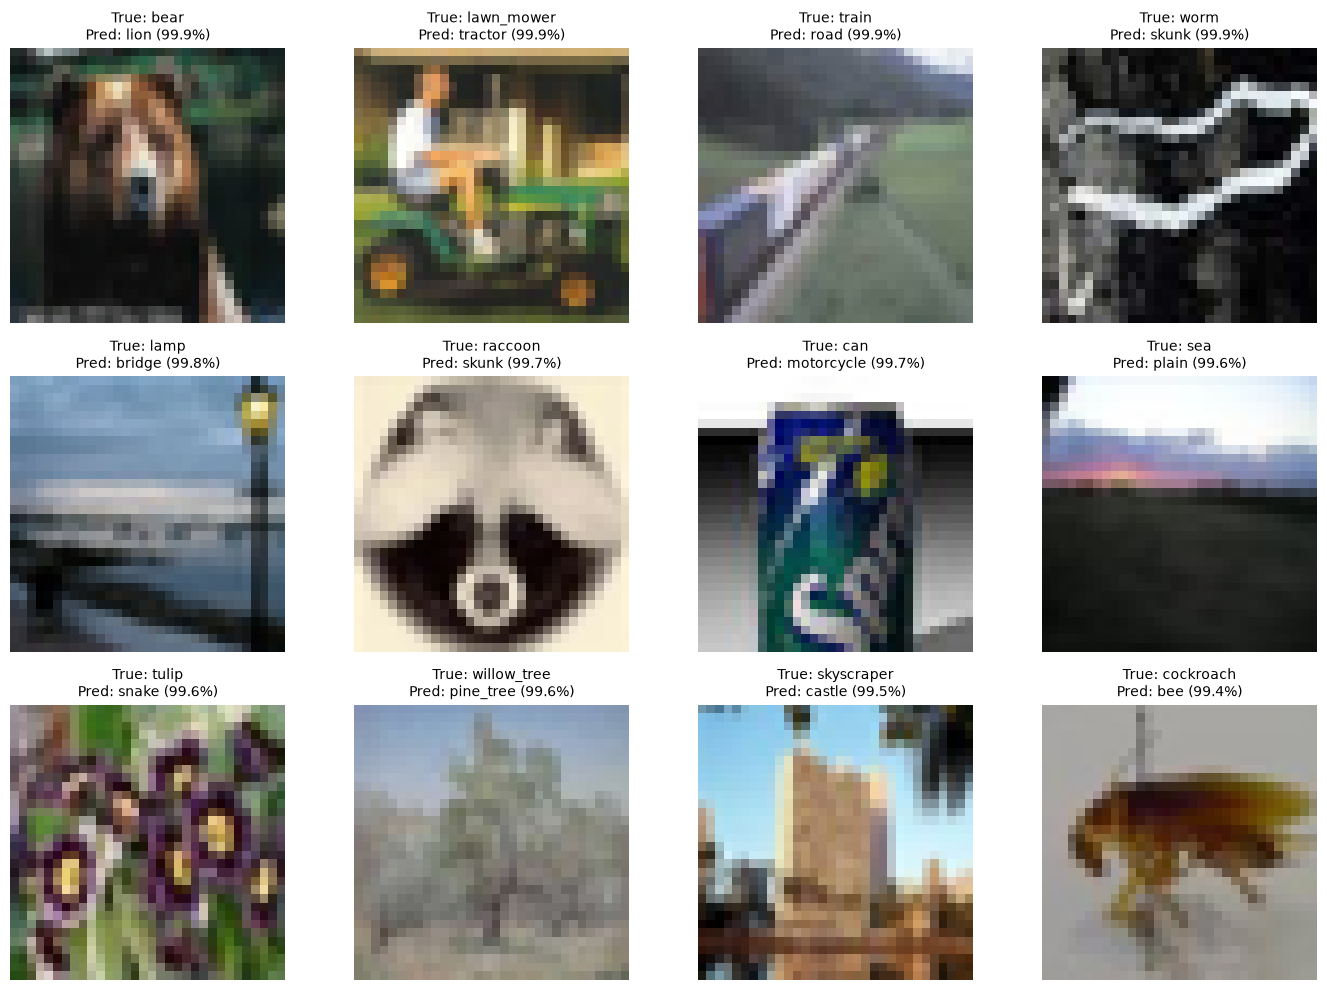

In [19]:
wrong_indices = torch.where(
    all_predictions != all_labels
)[0]

ranked_indices = wrong_indices[
    torch.argsort(
        all_confidences[wrong_indices],
        descending=True,
    )
][:12]

fig, axes = plt.subplots(3, 4, figsize=(14, 10))

for ax, position in zip(axes.flat, ranked_indices):
    i = position.item()
    image, label = val_loader.dataset[i]
    predicted = all_predictions[i].item()
    confidence = all_confidences[i].item()

    assert int(label) == all_labels[i].item()

    ax.imshow(image.detach().cpu().permute(1, 2, 0))
    ax.set_title(
        f"True: {class_names[int(label)]}\n"
        f"Pred: {class_names[predicted]} ({confidence:.1%})",
        fontsize=10,
    )
    ax.axis("off")

for ax in axes.flat[len(ranked_indices):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [20]:
model_adamw_bn.eval()

all_probs = []
all_targets = []
nll_sum = 0.0

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)
        labels = labels.to(device)

        logits = model_adamw_bn(images)

        # Compute NLL directly from logits for numerical stability.
        nll_sum += torch.nn.functional.cross_entropy(
            logits, labels, reduction="sum"
        ).item()

        all_probs.append(logits.softmax(dim=1).cpu())
        all_targets.append(labels.cpu())

probs = torch.cat(all_probs)
targets = torch.cat(all_targets)

confidence, predictions = probs.max(dim=1)
correct = predictions.eq(targets)
nll = nll_sum / targets.numel()

# Multiclass Brier score: sum over classes, then mean over examples.
one_hot = torch.nn.functional.one_hot(
    targets, num_classes=probs.shape[1]
).to(probs.dtype)

brier = (probs - one_hot).square().sum(dim=1).mean().item()

# Top-label ECE using 15 equal-width confidence bins.
n_bins = 15
bin_ids = (confidence * n_bins).long().clamp(max=n_bins - 1)
ece = 0.0

print("Confidence bins:")
for i in range(n_bins):
    mask = bin_ids.eq(i)
    count = mask.sum().item()

    if count == 0:
        continue

    bin_accuracy = correct[mask].float().mean().item()
    bin_confidence = confidence[mask].mean().item()
    ece += (count / targets.numel()) * abs(
        bin_accuracy - bin_confidence
    )

    print(
        f"[{i / n_bins:.2f}, {(i + 1) / n_bins:.2f}"
        f"{']' if i == n_bins - 1 else ')'} | "
        f"n={count:4d} | Accuracy={bin_accuracy:.2%} | "
        f"Confidence={bin_confidence:.2%}"
    )

print(f"\nValidation examples: {targets.numel():,}")
print(f"Accuracy:           {correct.float().mean().item():.2%}")
print(f"Mean confidence:    {confidence.mean().item():.2%}")
print(f"NLL:                {nll:.4f}")
print(f"Brier score:        {brier:.4f}")
print(f"ECE (15 bins):      {ece:.2%}")

Confidence bins:
[0.07, 0.13) | n=   3 | Accuracy=66.67% | Confidence=12.59%
[0.13, 0.20) | n=  37 | Accuracy=18.92% | Confidence=17.44%
[0.20, 0.27) | n=  83 | Accuracy=18.07% | Confidence=23.68%
[0.27, 0.33) | n= 157 | Accuracy=26.11% | Confidence=30.50%
[0.33, 0.40) | n= 242 | Accuracy=31.82% | Confidence=36.67%
[0.40, 0.47) | n= 247 | Accuracy=36.44% | Confidence=43.21%
[0.47, 0.53) | n= 286 | Accuracy=33.92% | Confidence=49.92%
[0.53, 0.60) | n= 252 | Accuracy=48.41% | Confidence=56.70%
[0.60, 0.67) | n= 278 | Accuracy=47.12% | Confidence=63.18%
[0.67, 0.73) | n= 269 | Accuracy=55.02% | Confidence=70.06%
[0.73, 0.80) | n= 282 | Accuracy=63.12% | Confidence=76.56%
[0.80, 0.87) | n= 316 | Accuracy=65.51% | Confidence=83.49%
[0.87, 0.93) | n= 446 | Accuracy=78.92% | Confidence=90.18%
[0.93, 1.00] | n=2102 | Accuracy=94.29% | Confidence=98.60%

Validation examples: 5,000
Accuracy:           68.98%
Mean confidence:    77.48%
NLL:                1.1840
Brier score:        0.4363
ECE (15

In [21]:
import time
import statistics
import torch

model_adamw_bn.eval()
parameter = model_adamw_bn.parameters()[0]
benchmark_device = parameter.device
is_cuda = benchmark_device.type == "cuda"

print("Device:", benchmark_device)
if is_cuda:
    print("GPU:", torch.cuda.get_device_name(benchmark_device))
print("Dtype:", parameter.dtype)

def synchronize():
    if is_cuda:
        torch.cuda.synchronize(benchmark_device)

@torch.inference_mode()
def benchmark(batch_size, warmup=20, repeats=100):
    x = torch.randn(
        batch_size, 3, 32, 32,
        device=benchmark_device,
        dtype=parameter.dtype,
    )

    for _ in range(warmup):
        model_adamw_bn(x)
    synchronize()

    if is_cuda:
        torch.cuda.reset_peak_memory_stats(benchmark_device)
        baseline_memory = torch.cuda.memory_allocated(benchmark_device)

    durations = []

    for _ in range(repeats):
        synchronize()
        start = time.perf_counter()

        output = model_adamw_bn(x)

        synchronize()
        durations.append(time.perf_counter() - start)
        del output

    mean_seconds = statistics.mean(durations)
    median_ms = statistics.median(durations) * 1000
    p95_ms = sorted(durations)[
        int(0.95 * (len(durations) - 1))
    ] * 1000

    print(f"\nBatch size: {batch_size}")
    print(f"Mean batch latency:   {mean_seconds * 1000:.3f} ms")
    print(f"Median batch latency: {median_ms:.3f} ms")
    print(f"P95 batch latency:    {p95_ms:.3f} ms")
    print(f"Throughput:           {batch_size / mean_seconds:.1f} images/s")

    if is_cuda:
        peak = torch.cuda.max_memory_allocated(benchmark_device)
        print(f"Peak allocated GPU memory: {peak / 2**20:.2f} MiB")
        print(
            "Peak increase above baseline: "
            f"{(peak - baseline_memory) / 2**20:.2f} MiB"
        )

for batch_size in (1, 32):
    benchmark(batch_size)

Device: cuda:0
GPU: NVIDIA GeForce RTX 5070 Ti Laptop GPU
Dtype: torch.float32

Batch size: 1
Mean batch latency:   8.841 ms
Median batch latency: 8.530 ms
P95 batch latency:    12.182 ms
Throughput:           113.1 images/s
Peak allocated GPU memory: 92.77 MiB
Peak increase above baseline: 7.06 MiB

Batch size: 32
Mean batch latency:   30.955 ms
Median batch latency: 30.854 ms
P95 batch latency:    37.452 ms
Throughput:           1033.8 images/s
Peak allocated GPU memory: 602.07 MiB
Peak increase above baseline: 232.81 MiB


In [25]:
selected_model = model_adamw_bn

restored_epoch = mini.load_checkpoint(
    "./checkpoints/best_inception_bn_cifar100_crop_adamw_ep20.pt",
    model_adamw_bn,
    device=device
)

assert restored_epoch == 18, (
    f"Expected selected epoch 18, got {restored_epoch}"
)

selected_model.eval()

test_metrics = mini.evaluate(
    selected_model,
    test_loader,
    device,
)

print("Model: Inception + BatchNorm + AdamW")
print(f"Selected epoch: {restored_epoch}")
print(f"Test examples:  {len(test_loader.dataset):,}")
print(f"Test loss:      {test_metrics['loss']:.4f}")
print(f"Test accuracy:  {test_metrics['accuracy']:.2f}%")

Model: Inception + BatchNorm + AdamW
Selected epoch: 18
Test examples:  10,000
Test loss:      1.1754
Test accuracy:  68.08%
